# G1.21 · Low-communication training: from local SGD to DiLoCo (+ compressed pseudo-gradients)

**ID:** G1.21 · **Target:** 110 min · **Plan week:** 15-16 · **Part:** G1

**The lab.** Everything in G1.11-G1.16 assumed you can afford a collective every step. Across datacenters or the
open internet (Prime Intellect's setting) you cannot: G1.10 measured ~3.5 GB/s between two GPUs in the *same*
box, and wide-area links are slower still. Guide G1: "Decentralized/async training at a high level
(DiLoCo-style low-communication training)". You will:
1. derive local SGD / FedAvg → **DiLoCo**: $K$ workers run $H$ inner AdamW steps on their own data shard, then one
   outer Nesterov step on the averaged **pseudo-gradient** $\Delta = \theta_\text{prev} - \theta_\text{local}$;
2. implement it with real ranks and prove two identities: outer SGD with lr 1 = parameter averaging, and
   $H=1$ with inner SGD = synchronous data parallel;
3. compare **validation loss vs communication rounds** against DDP at equal compute (same steps, same tokens) on a
   byte-level tinygpt trained on AG News, with i.i.d. and non-i.i.d. (by-topic) worker shards;
4. compress the all-reduced pseudo-gradient: fp16 (OpenDiLoCo) and an **int8 ring all-reduce with fp32
   accumulation** (INTELLECT-1);
5. read short sections on Streaming DiLoCo, DeMo, fault tolerance / elastic membership, and asynchronous RL
   (INTELLECT-2 / prime-rl), and why Prime Intellect builds on all of them.

## Sources
- A. Douillard, Q. Feng, A. A. Rusu, R. Chhaparia, Y. Donchev, A. Kuncoro, M. Ranzato, A. Szlam, J. Shen,
  *DiLoCo: Distributed Low-Communication Training of Language Models*, 2023, arXiv:2311.08105 —
  https://arxiv.org/abs/2311.08105 (Algorithm 1; inner AdamW lr 4e-4, outer Nesterov lr 0.7, momentum 0.9, H = 500
  in the main experiments, Table 5; "8 workers performs as well as fully synchronous optimization while
  communicating 500 times less"; outer SGD = FedAvg; H = 1 with inner SGD = large-batch DP).
- S. Jaghouar, J. M. Ong, J. Hagemann, *OpenDiLoCo: An Open-Source Framework for Globally Distributed
  Low-Communication Training*, 2024, arXiv:2407.07852 (pseudo-gradients all-reduced in FP16 without degradation).
  Code: PrimeIntellect-ai/OpenDiloco@2d750e5 `open_diloco/train_diloco_torch.py` (Apache-2.0): offloaded
  snapshot, `param.grad = snapshot - param`, `all_reduce(AVG)`, outer `SGD(lr=0.7, momentum=0.9, nesterov=True)`.
  Our outer step adapts that loop.
- S. Jaghouar, J. M. Ong, M. Basra, F. Obeid, J. Straube, M. Keiblinger et al. (Prime Intellect), *INTELLECT-1
  Technical Report*, 2024, arXiv:2412.01152 (10B model, up to 14 nodes on 3 continents, 30 providers joining and
  leaving; DiLoCo with 100 inner steps; int8 ring all-reduce with fp32 accumulation, "Q(a)+Q(b) ≠ Q(a+b)";
  400× less bandwidth than DP; ElasticDeviceMesh, heartbeats, outer Nesterov lr 0.7 / 0.9).
- A. Douillard, Y. Donchev, K. Rush, S. Kale, Z. Charles, Z. Garrett et al., *Streaming DiLoCo with overlapping
  communication: Towards a Distributed Free Lunch*, 2025, arXiv:2501.18512 (sync fragments of layers in sequence,
  overlap communication with inner steps, E3M0 4-bit outer gradients; 400× fewer bits than DP).
- Z. Charles et al., *Communication-Efficient Language Model Training Scales Reliably and Robustly: Scaling Laws
  for DiLoCo*, 2025, arXiv:2503.09799.
- B. Peng, L. Chen, B. Su, J. Quesnelle, D. P. Kingma et al., *DeMo: Decoupled Momentum Optimization*, 2024,
  arXiv:2411.19870 (local momentum, DCT + top-k of the fast components, error feedback; up to 85× less data per
  GPU than AdamW-DDP in their experiments).
- T. Lin, S. U. Stich, K. K. Patel, M. Jaggi, *Don't Use Large Mini-Batches, Use Local SGD*, ICLR 2020,
  arXiv:1808.07217; S. U. Stich, *Local SGD Converges Fast and Communicates Little*, ICLR 2019, arXiv:1805.09767.
- Prime Intellect Team, S. Jaghouar, J. Mattern, J. M. Ong, J. Straube et al., *INTELLECT-2: A Reasoning Model
  Trained Through Globally Decentralized Reinforcement Learning*, 2025, arXiv:2505.07291 (PRIME-RL: decoupled
  rollout / training / weight broadcast; two-step asynchrony; TOPLOC verification of untrusted inference;
  SHARDCAST weight distribution; two-sided GRPO clipping). Code: https://github.com/PrimeIntellect-ai/prime-rl
- AG News (Zhang, Zhao, LeCun, *Character-level Convolutional Networks for Text Classification*, NeurIPS 2015,
  arXiv:1509.01626) from `prep.DATA / "ag_news"`.

## 1. From synchronous DP to DiLoCo
**Synchronous DP** (G1.11): every step $\theta \leftarrow \theta - \eta\,\mathrm{opt}(\frac1K\sum_k g_k)$, one
gradient all-reduce per step.

**Local SGD / FedAvg** (Stich 2019; Lin et al. 2020): each worker takes $H$ local steps from the shared
$\theta$, then the parameters are averaged. Communication drops by $H\times$; the price is that workers drift
apart on different data.

**DiLoCo** (Douillard et al. 2023, Algorithm 1) for outer step $t$:
$$\theta_k \leftarrow \theta^{(t-1)};\quad \theta_k \leftarrow \text{InnerOpt}^{H}(\theta_k; \mathcal D_k)\ \ (\text{AdamW, } H \text{ steps});\quad
\Delta^{(t)} = \frac1K\sum_k\big(\theta^{(t-1)} - \theta_k\big);\quad \theta^{(t)} \leftarrow \text{OuterOpt}(\theta^{(t-1)}, \Delta^{(t)}).$$
The **pseudo-gradient** $\Delta$ is treated as a gradient by an outer optimizer: Nesterov momentum SGD, lr 0.7,
momentum 0.9 (robust across their sweeps; Table 5). Special cases you will check numerically:
- OuterOpt = SGD(lr = 1, no momentum) → $\theta^{(t)} = \frac1K\sum_k\theta_k$: **parameter averaging** (FedAvg).
- $H = 1$, InnerOpt = SGD(lr $\eta$), OuterOpt = SGD(lr 1) → $\theta - \eta\frac1K\sum_k g_k$: **synchronous DP**.

Each worker keeps its own inner AdamW state across rounds (it is never communicated). The outer momentum state
is identical on all workers, since they all see the same $\Delta$. Communication per round: one all-reduce of
$\Psi$ values, every $H$ steps instead of every step.

```
worker k:  θ ──AdamW×H on D_k──> θ_k ─┐
                                      ├─ all-reduce mean of (θ_prev - θ_k) = Δ ─> Nesterov(θ_prev, Δ) ─> θ (all workers)
worker j:  θ ──AdamW×H on D_j──> θ_j ─┘
```

**Your task (in the script below):** `outer_step` (pseudo-gradient → averaged with a pluggable all-reduce →
outer optimizer → new snapshot), and two compressed all-reduces of the pseudo-gradient:
- `allreduce_fp16`: divide by $K$, cast to fp16, all-reduce, cast back (OpenDiLoCo);
- `allreduce_int8_ring`: the ring all-reduce from G1.10, but every chunk travels as **int8 + one fp32 scale**
  (symmetric absmax quantization). The receiver dequantizes and **accumulates in fp32**: INTELLECT-1 notes
  $Q(a)+Q(b) \ne Q(a+b)$, so never add in int8. Subtle point: in the all-gather phase every rank, including the
  chunk's owner, must store the *dequantized* value, otherwise replicas silently diverge.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from prep import DATA, Session, check, check_close

s = Session("G1.21", target_min=110)
NGPU = torch.cuda.device_count()
NPROC = min(4, NGPU) if NGPU >= 2 else 2
BACKEND = "nccl" if NGPU >= 2 else "gloo"
RUN = Path("runs_G1.21")
RUN.mkdir(exist_ok=True)


def torchrun(script, *args, nproc=NPROC, timeout=900):
    """Run `torchrun --standalone --nproc_per_node={nproc} script args` inside RUN/; raise if any rank fails."""
    args = [str(a) for a in args]
    print(f"$ torchrun --standalone --nproc_per_node={nproc} {script} {' '.join(args)}")
    env = {**os.environ, "BACKEND": BACKEND, "OMP_NUM_THREADS": "2", "AG_NEWS": str(DATA / "ag_news")}
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}", script, *args]
    p = subprocess.run(cmd, cwd=RUN, capture_output=True, text=True, timeout=timeout, env=env)
    print(p.stdout)
    if p.returncode != 0:
        print(p.stderr[-6000:])
        raise RuntimeError(f"{script} exited with code {p.returncode}")


def load(name):
    return json.loads((RUN / name).read_text())

[G1.21] started 16:53; target 110 min


In [2]:
%%writefile runs_G1.21/my_diloco.py
import torch
import torch.distributed as dist


def allreduce_mean(x):
    """Baseline: fp32 all-reduce (mean). Returns (result, bytes this rank put on the wire, ring model)."""
    n = dist.get_world_size()
    y = x.clone()
    dist.all_reduce(y)
    return y / n, 2 * (n - 1) / n * y.numel() * 4


def allreduce_fp16(x):
    """Mean over ranks with fp16 on the wire."""
    n = dist.get_world_size()
    y = (x / n).to(torch.float16)
    dist.all_reduce(y)
    return y.float(), 2 * (n - 1) / n * y.numel() * 2


def quantize_int8(x):
    """Symmetric absmax: x ~ q * scale, q in [-127, 127]."""
    scale = x.abs().max().clamp_min(1e-12) / 127.0
    return torch.round(x / scale).clamp(-127, 127).to(torch.int8), scale.reshape(1).float()


def dequantize_int8(q, scale):
    return q.float() * scale


def _send_recv_q(chunk_q, scale, recv_numel, right, left, dev):
    rq = torch.empty(recv_numel, dtype=torch.int8, device=dev)
    rs = torch.empty(1, device=dev)
    ops = [dist.P2POp(dist.isend, chunk_q, right), dist.P2POp(dist.isend, scale, right),
           dist.P2POp(dist.irecv, rq, left), dist.P2POp(dist.irecv, rs, left)]
    for r in dist.batch_isend_irecv(ops):
        r.wait()
    return rq, rs


def allreduce_int8_ring(x):
    """Mean over ranks; ring reduce-scatter + all-gather where every hop carries int8 + an fp32 scale."""
    rank, n, dev = dist.get_rank(), dist.get_world_size(), x.device
    chunks = [c.clone() for c in torch.tensor_split(x.flatten().float(), n)]
    right, left = (rank + 1) % n, (rank - 1) % n
    sent = 0
    for t in range(n - 1):                                     # reduce-scatter, fp32 accumulation
        si, ri = (rank - t) % n, (rank - t - 1) % n
        q, sc = quantize_int8(chunks[si])
        rq, rs = _send_recv_q(q, sc, chunks[ri].numel(), right, left, dev)
        chunks[ri] += dequantize_int8(rq, rs)
        sent += q.numel() + 4
    own = (rank + 1) % n                                       # fully reduced chunk on this rank
    q, sc = quantize_int8(chunks[own])
    chunks[own] = dequantize_int8(q, sc)                       # owner keeps the SAME value everyone else gets
    for t in range(n - 1):                                     # all-gather of quantized final chunks
        si, ri = (rank + 1 - t) % n, (rank - t) % n
        q, sc = quantize_int8(chunks[si])
        rq, rs = _send_recv_q(q, sc, chunks[ri].numel(), right, left, dev)
        chunks[ri] = dequantize_int8(rq, rs)
        sent += q.numel() + 4
    return torch.cat(chunks).view_as(x) / n, sent


@torch.no_grad()
def outer_step(model, snapshot, outer_opt, allreduce=allreduce_mean):
    """DiLoCo outer step. snapshot: list of tensors = theta_prev (same on all ranks). Mutates model params to the new
    global theta, refreshes snapshot in place, returns bytes sent by this rank."""
    params = [p for p in model.parameters()]
    sent = 0
    for p, s_ in zip(params, snapshot):
        delta, b = allreduce(s_ - p.detach())                 # pseudo-gradient, averaged over workers
        sent += b
        p.copy_(s_)                                            # back to theta_prev ...
        p.grad = delta.view_as(p).to(p.dtype)                  # ... and let the outer optimizer step along -delta
    outer_opt.step()
    outer_opt.zero_grad(set_to_none=True)
    for p, s_ in zip(params, snapshot):
        s_.copy_(p.detach())
    return sent

Overwriting runs_G1.21/my_diloco.py


## 2. Identities first
Before any experiment, prove the special cases with real ranks on a small MLP: (a) DiLoCo with
$H=1$, inner SGD and outer SGD(lr = 1) must equal synchronous DP with SGD; (b) outer SGD(lr = 1) must equal plain
parameter averaging; (c) the compressed all-reduces must be close to the fp32 mean (int8: within one
quantization step per hop) and must leave **all replicas bitwise identical**.

In [3]:
%%writefile runs_G1.21/check_diloco.py
import copy
import json
import os

import torch
import torch.distributed as dist
import torch.nn as nn

from my_diloco import allreduce_fp16, allreduce_int8_ring, allreduce_mean, outer_step

backend = os.environ.get("BACKEND", "nccl")
lr_ = int(os.environ["LOCAL_RANK"])
dev = torch.device("cuda", lr_) if backend == "nccl" else torch.device("cpu")
if backend == "nccl":
    torch.cuda.set_device(dev)
dist.init_process_group(backend, device_id=dev if backend == "nccl" else None)
rank, K = dist.get_rank(), dist.get_world_size()
torch.backends.cuda.matmul.allow_tf32 = False


def mlp():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(8, 32), nn.Tanh(), nn.Linear(32, 1)).to(dev)


def data(step, r):
    g = torch.Generator().manual_seed(1000 * step + r)
    x = torch.randn(16, 8, generator=g)
    return x.to(dev), x.sum(1, keepdim=True).sin().to(dev)


def maxdiff_across_ranks(model):
    flat = torch.cat([p.detach().flatten() for p in model.parameters()])
    ref = flat.clone()
    dist.broadcast(ref, 0)
    e = torch.tensor([(flat - ref).abs().max().item()], device=dev)
    dist.all_reduce(e, op=dist.ReduceOp.MAX)
    return e.item()


res = {"K": K}
# (a) H=1, inner SGD, outer SGD lr=1  ==  synchronous DP with SGD
ddp, dl = mlp(), mlp()
opt_d = torch.optim.SGD(ddp.parameters(), lr=0.1)
inner = torch.optim.SGD(dl.parameters(), lr=0.1)
outer = torch.optim.SGD(dl.parameters(), lr=1.0)
snap = [p.detach().clone() for p in dl.parameters()]
for step in range(20):
    x, y = data(step, rank)
    opt_d.zero_grad()
    nn.functional.mse_loss(ddp(x), y).backward()
    for p in ddp.parameters():
        dist.all_reduce(p.grad)
        p.grad /= K
    opt_d.step()
    inner.zero_grad()
    nn.functional.mse_loss(dl(x), y).backward()
    inner.step()
    outer_step(dl, snap, outer)
res["H1_equals_DP"] = max((p - q).abs().max().item() for p, q in zip(ddp.parameters(), dl.parameters()))

# (b) outer SGD lr=1 == parameter averaging (H = 5 AdamW steps)
m = mlp()
inner = torch.optim.AdamW(m.parameters(), lr=1e-2)
outer = torch.optim.SGD(m.parameters(), lr=1.0)
snap = [p.detach().clone() for p in m.parameters()]
for step in range(5):
    x, y = data(step, rank)
    inner.zero_grad()
    nn.functional.mse_loss(m(x), y).backward()
    inner.step()
avg = [p.detach().clone() for p in m.parameters()]
for a in avg:
    dist.all_reduce(a)
    a /= K
outer_step(m, snap, outer)
res["lr1_equals_averaging"] = max((p - a).abs().max().item() for p, a in zip(m.parameters(), avg))
res["snapshot_refreshed"] = max((p - s_).abs().max().item() for p, s_ in zip(m.parameters(), snap))

# (c) compressed all-reduces
torch.manual_seed(rank)
x = torch.randn(10_001, device=dev) * 1e-3
ref, b32 = allreduce_mean(x)
for name, fn in (("fp16", allreduce_fp16), ("int8", allreduce_int8_ring)):
    y, b = fn(x)
    yy = y.flatten().clone()
    y0 = yy.clone()
    dist.broadcast(y0, 0)
    e = torch.tensor([(y - ref).abs().max().item(), (yy - y0).abs().max().item()], device=dev)
    dist.all_reduce(e, op=dist.ReduceOp.MAX)
    res[name] = {"max_err": e[0].item(), "replica_diff": e[1].item(), "bytes_ratio_vs_fp32": b / b32,
                 "absmax": x.abs().max().item()}
if rank == 0:
    print(json.dumps(res, indent=1))
    json.dump(res, open("check_diloco.json", "w"))
dist.destroy_process_group()

Overwriting runs_G1.21/check_diloco.py


In [4]:
torchrun("check_diloco.py")
c = load("check_diloco.json")
check("H=1 + inner SGD + outer SGD(lr=1) == synchronous DP", c["H1_equals_DP"] < 1e-6, f"{c['H1_equals_DP']:.2e}")
check("outer SGD(lr=1) == parameter averaging", c["lr1_equals_averaging"] < 1e-6, f"{c['lr1_equals_averaging']:.2e}")
check("snapshot holds the new global parameters", c["snapshot_refreshed"] == 0.0)
K = c["K"]
check("fp16 all-reduce close to fp32 mean", c["fp16"]["max_err"] < 1e-3 * c["fp16"]["absmax"] + 1e-7, str(c["fp16"]))
# int8: each of the K-1 reduce hops and the final broadcast add at most half a quantization step of the running sum
check("int8 ring all-reduce within quantization error", c["int8"]["max_err"] < K * c["int8"]["absmax"] / 127, str(c["int8"]))
for name in ("fp16", "int8"):
    check(f"{name}: replicas bitwise identical", c[name]["replica_diff"] == 0.0, str(c[name]["replica_diff"]))
check_close("fp16 sends 1/2 the bytes of fp32", c["fp16"]["bytes_ratio_vs_fp32"], 0.5, rtol=1e-3)
check_close("int8 ring sends ~1/4 the bytes of fp32", c["int8"]["bytes_ratio_vs_fp32"], 0.25, rtol=0.01)

$ torchrun --standalone --nproc_per_node=4 check_diloco.py 


{
 "K": 4,
 "H1_equals_DP": 2.086162567138672e-07,
 "lr1_equals_averaging": 2.9802322387695312e-08,
 "snapshot_refreshed": 0.0,
 "fp16": {
  "max_err": 1.2514647096395493e-06,
  "replica_diff": 0.0,
  "bytes_ratio_vs_fp32": 0.5,
  "absmax": 0.004230118356645107
 },
 "int8": {
  "max_err": 2.034533827099949e-05,
  "replica_diff": 0.0,
  "bytes_ratio_vs_fp32": 0.2504082925040829,
  "absmax": 0.004230118356645107
 }
}

ok  H=1 + inner SGD + outer SGD(lr=1) == synchronous DP
ok  outer SGD(lr=1) == parameter averaging
ok  snapshot holds the new global parameters
ok  fp16 all-reduce close to fp32 mean
ok  int8 ring all-reduce within quantization error
ok  fp16: replicas bitwise identical
ok  int8: replicas bitwise identical
ok  fp16 sends 1/2 the bytes of fp32
ok  int8 ring sends ~1/4 the bytes of fp32


## 3. DiLoCo vs DDP at equal compute
Workload: byte-level tinygpt (vocab 256, 4 layers, $d$ = 128, context 128; ≈ 0.8M parameters) on AG News text.
Each of the $K$ ranks is a "worker" with its own shard of the training documents:
- **i.i.d.:** documents dealt round-robin;
- **non-i.i.d.:** worker $k$ only sees news topics $\{c : c \bmod K = k\}$ (World / Sports / Business /
  Sci-Tech), a strong distribution shift between workers.

All runs start from the **same warm-started model** (rank 0 trains 500 AdamW steps, then broadcasts), as in the
DiLoCo paper's main experiments, which start from a pretrained checkpoint. Then every run does the same $T = 1000$
inner steps per worker with the same per-worker batch, so the same FLOPs and tokens. Validation loss is measured on held-out documents from all topics, always on the **globally
synchronized** model (for DiLoCo, right after an outer step). Runs:
- `ddp`: AdamW on the all-reduced gradient, $T$ communication rounds;
- `diloco_H`: inner AdamW for $H$ steps, outer Nesterov(0.7, 0.9), $T/H$ rounds; $H \in \{10, 50, 200\}$ here.
  The paper uses $H=500$ for runs with tens of thousands of steps, so here $H$ is scaled to the run length;
- `local_sgd_50`: same, but outer SGD(lr = 1): parameter averaging;
- `diloco_50_int8`: DiLoCo with the int8 ring all-reduce;
- `no_comm`: workers never sync (evaluate worker 0): the lower bound on what communication buys.

Learning rate: the same AdamW lr (1e-3, cosine decay) for DDP and the inner optimizer, as in the DiLoCo paper's
setup. DDP's effective batch is $K\times$ larger per step. (Stretch: set `PRE = 0`. In our ~20-round run from
scratch the outer momentum has no time to help and DiLoCo lags DDP noticeably. The paper's Fig. 3 finds starting
from scratch costs only ~0.1 PPL, but over 88k steps, i.e. hundreds of outer rounds.)

In [5]:
%%writefile runs_G1.21/diloco.py
import json
import math
import os
import sys
import time

import numpy as np
import pandas as pd
import torch
import torch.distributed as dist

from my_diloco import allreduce_int8_ring, allreduce_mean, outer_step
from prep.tinygpt import GPT, GPTConfig

backend = os.environ.get("BACKEND", "nccl")
lr_ = int(os.environ["LOCAL_RANK"])
dev = torch.device("cuda", lr_) if backend == "nccl" else torch.device("cpu")
if backend == "nccl":
    torch.cuda.set_device(dev)
dist.init_process_group(backend, device_id=dev if backend == "nccl" else None)
rank, K = dist.get_rank(), dist.get_world_size()
cuda = dev.type == "cuda"
T_STEPS, PRE = (1000, 500) if cuda else (300, 200)   # inner steps per run, shared warm-start steps
B, CTX, LR = 16, 128, 1e-3
cfg = GPTConfig(vocab_size=256, context_length=CTX, d_model=128, n_heads=4, n_layers=4, tie_weights=True)

# ---- data: bytes of AG News documents; worker shards (iid or by topic), shared validation set
df = pd.read_parquet(os.path.join(os.environ["AG_NEWS"], "train.parquet")).iloc[:40000]
val_df = pd.read_parquet(os.path.join(os.environ["AG_NEWS"], "test.parquet")).iloc[:2000]


def to_bytes(texts):
    return torch.tensor(np.frombuffer(("\n".join(texts)).encode("utf-8", "replace"), dtype=np.uint8).astype(np.int64))


shards = {"iid": to_bytes(df.text[rank::K].tolist()),
          "noniid": to_bytes(df.text[(df.label % K) == rank].tolist())}
val = to_bytes(val_df.text.tolist())
g_val = torch.Generator().manual_seed(0)
val_idx = torch.randint(0, len(val) - CTX - 1, (64,), generator=g_val)
VX = torch.stack([val[i:i + CTX] for i in val_idx]).to(dev)
VY = torch.stack([val[i + 1:i + CTX + 1] for i in val_idx]).to(dev)


shards = {k: v.to(dev) for k, v in shards.items()}
AR = torch.arange(CTX + 1, device=dev)


def batch(data, gen):
    idx = torch.randint(0, len(data) - CTX - 1, (B,), generator=gen).to(dev)
    w = data[idx[:, None] + AR]
    return w[:, :-1], w[:, 1:]


@torch.no_grad()
def val_loss(model):
    model.eval()
    l = model(VX, VY)[1].item()
    model.train()
    return l


def lr_at(step):                                   # cosine decay to 10% (after the warm start)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(step, T_STEPS) / T_STEPS)))


# shared warm start (as in the DiLoCo paper's main setting): rank 0 trains PRE steps, then broadcasts
torch.manual_seed(0)
BASE = GPT(cfg).to(dev)
if rank == 0:
    o = torch.optim.AdamW(BASE.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
    gw = torch.Generator().manual_seed(7)
    for i in range(PRE):
        for gr in o.param_groups:
            gr["lr"] = LR * min(1, (i + 1) / 50)
        x, y = batch(shards["iid"], gw)
        o.zero_grad()
        BASE(x, y)[1].backward()
        o.step()
for p in BASE.parameters():
    dist.broadcast(p.data, 0)


def run(kind, H=1, shard="iid", outer_lr=0.7, outer_mom=0.9, allreduce=allreduce_mean):
    model = GPT(cfg).to(dev)
    model.load_state_dict(BASE.state_dict())
    inner = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
    outer = torch.optim.SGD(model.parameters(), lr=outer_lr, momentum=outer_mom, nesterov=outer_mom > 0)
    snap = [p.detach().clone() for p in model.parameters()]
    gen = torch.Generator().manual_seed(100 + rank)
    curve, rounds, sent = [(0, 0, val_loss(model))], 0, 0.0
    for step in range(T_STEPS):
        for gr in inner.param_groups:
            gr["lr"] = lr_at(step)
        x, y = batch(shards[shard], gen)
        inner.zero_grad(set_to_none=True)
        model(x, y)[1].backward()
        if kind == "ddp":
            for p in model.parameters():
                dist.all_reduce(p.grad)
                p.grad /= K
                sent += 2 * (K - 1) / K * p.numel() * 4
            rounds += 1
        inner.step()
        if kind == "diloco" and (step + 1) % H == 0:
            sent += outer_step(model, snap, outer, allreduce)
            rounds += 1
            curve.append((step + 1, rounds, val_loss(model)))
        elif kind == "ddp" and (step + 1) % 50 == 0:
            curve.append((step + 1, rounds, val_loss(model)))
        elif kind == "no_comm" and (step + 1) % 50 == 0:
            curve.append((step + 1, 0, val_loss(model)))
    return {"curve": curve, "final": curve[-1][2], "rounds": rounds, "MB_sent": sent / 1e6}


t0 = time.time()
configs = {
    "ddp": dict(kind="ddp"),
    "diloco_10": dict(kind="diloco", H=10),
    "diloco_50": dict(kind="diloco", H=50),
    "diloco_200": dict(kind="diloco", H=200 if cuda else 100),
    "local_sgd_50": dict(kind="diloco", H=50, outer_lr=1.0, outer_mom=0.0),
    "diloco_50_int8": dict(kind="diloco", H=50, allreduce=allreduce_int8_ring),
    "no_comm": dict(kind="no_comm"),
    "ddp_noniid": dict(kind="ddp", shard="noniid"),
    "diloco_50_noniid": dict(kind="diloco", H=50, shard="noniid"),
    "no_comm_noniid": dict(kind="no_comm", shard="noniid"),
}
res = {"K": K, "T": T_STEPS, "params": sum(p.numel() for p in GPT(cfg).parameters())}
for name, kw in configs.items():
    res[name] = run(**kw)
    if rank == 0:
        r = res[name]
        print(f"{name:18s} final val loss {r['final']:.3f}  rounds {r['rounds']:4d}  sent {r['MB_sent']:8.1f} MB/rank "
              f"({time.time() - t0:.0f}s)")
if rank == 0:
    json.dump(res, open("diloco.json", "w"))
dist.destroy_process_group()

Overwriting runs_G1.21/diloco.py


$ torchrun --standalone --nproc_per_node=4 diloco.py 


ddp                final val loss 1.684  rounds 1000  sent   5042.7 MB/rank (18s)
diloco_10          final val loss 1.576  rounds  100  sent    504.3 MB/rank (33s)
diloco_50          final val loss 1.727  rounds   20  sent    100.9 MB/rank (46s)
diloco_200         final val loss 1.895  rounds    5  sent     25.2 MB/rank (59s)
local_sgd_50       final val loss 1.898  rounds   20  sent    100.9 MB/rank (73s)
diloco_50_int8     final val loss 1.727  rounds   20  sent     25.2 MB/rank (88s)
no_comm            final val loss 1.953  rounds    0  sent      0.0 MB/rank (101s)
ddp_noniid         final val loss 1.689  rounds 1000  sent   5042.7 MB/rank (118s)
diloco_50_noniid   final val loss 1.707  rounds   20  sent    100.9 MB/rank (132s)
no_comm_noniid     final val loss 2.033  rounds    0  sent      0.0 MB/rank (144s)

K=4 workers, T=1000 inner steps each, 0.84M params
run                val loss  rounds   MB/rank
ddp                   1.684    1000    5042.7
diloco_10             1.576     

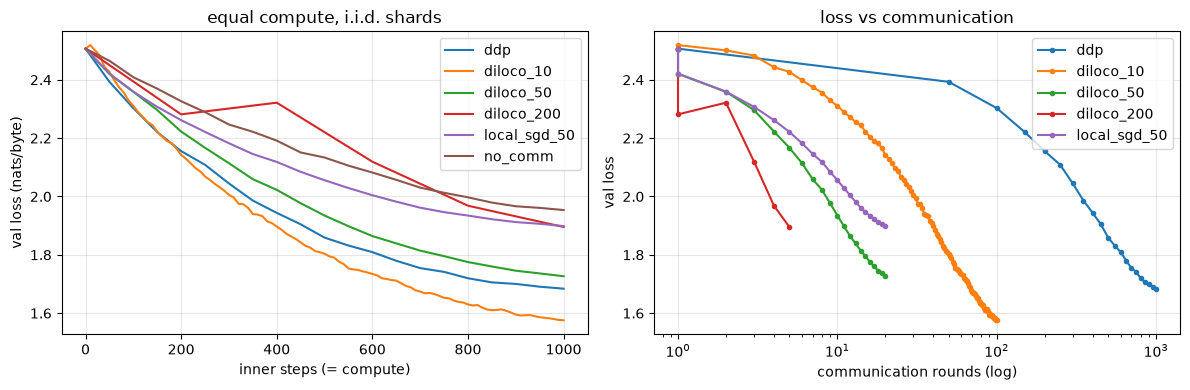

In [6]:
torchrun("diloco.py")
d = load("diloco.json")
print(f"K={d['K']} workers, T={d['T']} inner steps each, {d['params']/1e6:.2f}M params")
print(f"{'run':18s} {'val loss':>8s} {'rounds':>7s} {'MB/rank':>9s}")
for name in ("ddp", "diloco_10", "diloco_50", "diloco_200", "local_sgd_50", "diloco_50_int8", "no_comm",
             "ddp_noniid", "diloco_50_noniid", "no_comm_noniid"):
    r = d[name]
    print(f"{name:18s} {r['final']:8.3f} {r['rounds']:7d} {r['MB_sent']:9.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in ("ddp", "diloco_10", "diloco_50", "diloco_200", "local_sgd_50", "no_comm"):
    cv = np.array(d[name]["curve"])
    ax[0].plot(cv[:, 0], cv[:, 2], label=name)
    if name != "no_comm":
        ax[1].semilogx(np.maximum(cv[:, 1], 1), cv[:, 2], "o-", ms=3, label=name)
ax[0].set(xlabel="inner steps (= compute)", ylabel="val loss (nats/byte)", title="equal compute, i.i.d. shards")
ax[1].set(xlabel="communication rounds (log)", ylabel="val loss", title="loss vs communication")
for a in ax:
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
gap = d["diloco_50"]["final"] - d["ddp"]["final"]
print(f"DiLoCo(H=50) - DDP = {gap:+.3f} nats with {d['ddp']['rounds'] / d['diloco_50']['rounds']:.0f}x fewer rounds")
check("DiLoCo (H=50) within 0.15 nats of DDP at equal compute", gap < 0.15, f"gap {gap:.3f}")
check("communicating helps: DiLoCo beats isolated workers", d["diloco_50"]["final"] < d["no_comm"]["final"] - 0.02)
check("Nesterov outer step beats plain averaging (local SGD) at H=50",
      d["diloco_50"]["final"] < d["local_sgd_50"]["final"])
check("int8 pseudo-gradients cost almost nothing (< 0.03 nats)",
      abs(d["diloco_50_int8"]["final"] - d["diloco_50"]["final"]) < 0.03)
check_close("int8 sends ~4x fewer bytes than fp32 DiLoCo", d["diloco_50"]["MB_sent"] / d["diloco_50_int8"]["MB_sent"], 4.0,
            rtol=0.02)
check("non-iid shards: DiLoCo still far better than isolated workers",
      d["diloco_50_noniid"]["final"] < d["no_comm_noniid"]["final"] - 0.05)
print(f"bytes per rank: DDP {d['ddp']['MB_sent']:.0f} MB vs DiLoCo-50 {d['diloco_50']['MB_sent']:.1f} MB "
      f"vs DiLoCo-50-int8 {d['diloco_50_int8']['MB_sent']:.1f} MB "
      f"({d['ddp']['MB_sent'] / d['diloco_50_int8']['MB_sent']:.0f}x less than DDP)")

DiLoCo(H=50) - DDP = +0.043 nats with 50x fewer rounds
ok  DiLoCo (H=50) within 0.15 nats of DDP at equal compute
ok  communicating helps: DiLoCo beats isolated workers
ok  Nesterov outer step beats plain averaging (local SGD) at H=50
ok  int8 pseudo-gradients cost almost nothing (< 0.03 nats)
ok  int8 sends ~4x fewer bytes than fp32 DiLoCo
ok  non-iid shards: DiLoCo still far better than isolated workers
bytes per rank: DDP 5043 MB vs DiLoCo-50 100.9 MB vs DiLoCo-50-int8 25.2 MB (200x less than DDP)


**What to take away.** At equal compute, DiLoCo with $H = 50$ lands within a few hundredths of a nat of synchronous
DP while communicating $50\times$ less often, and with int8 pseudo-gradients $200\times$ fewer bytes. In our runs
it was slightly below DDP with $K=2$ workers and ~0.07 above with $K=4$: at fixed total compute the gap grows
with the number of workers.
Larger $H$ (200: only 5 rounds) degrades toward the isolated-worker baseline. The paper reports parity at
$H = 500$ for 8 workers on C4, and INTELLECT-1 ran $H = 100$ with int8 for a 400× reduction. The Nesterov outer
step matters: plain parameter averaging (local SGD) is worse at the same $H$ (Douillard et al. Fig. 6 find SGD
and Adam outer optimizers inferior). With non-i.i.d. shards, isolated workers specialize and do badly on the
mixed validation set, while DiLoCo's averaged model stays close to DDP. This tiny run is a sanity check, not a
scaling study. The DiLoCo scaling-law paper (Charles et al. 2025) studies how the gap behaves with model size and
$K$.

## 4. Beyond DiLoCo (read; be able to explain)
**Streaming DiLoCo** (Douillard et al. 2025). Plain DiLoCo still needs a burst of $\Psi$ values every $H$ steps,
and the peak bandwidth is unchanged. Streaming DiLoCo (1) splits the model into $P$ fragments of transformer blocks
(sequential or strided) and synchronizes one fragment at a time on a staggered schedule, cutting peak bandwidth
~$P\times$; (2) **overlaps** a fragment's all-reduce with the next $\tau$ inner steps and then mixes the
received global fragment with the locally updated one (mixing factor $\alpha$), so communication latency up to
a full step is tolerated; (3) sends outer gradients in 4-bit E3M0 floats while accumulating in fp32. On a 1B model
they match DP quality with 400× fewer bits exchanged.

**DeMo** (Peng et al. 2024). Instead of syncing rarely, sync a *little* every step. Each worker keeps its own
momentum, extracts the fast-moving components with a DCT + top-$k$, all-gathers only those, and subtracts
them from the local momentum (error feedback). The optimizer then steps with the gathered components. Up to 85×
less data per GPU than AdamW-DDP in their 300M/1B experiments. A cousin of PowerSGD-style gradient compression.

**Fault tolerance and elastic membership.** With $H$ steps between syncs, a worker can join, leave or crash
between rounds without stalling everyone. INTELLECT-1's ElasticDeviceMesh keeps two kinds of process groups:
fast intra-node ones (FSDP2) and a fault-tolerant global group for the outer all-reduce that is rebuilt when
membership changes. Nodes heartbeat every 2 s and are evicted after 6 s of silence. New nodes download a
checkpoint from a peer and join at the next outer step with a zero pseudo-gradient. The DiLoCo paper also shows
robustness to workers dropping or being added during training. Synchronous DDP has none of this: one dead rank
hangs every collective (G1.10).

**Asynchronous RL (INTELLECT-2 / prime-rl).** RL post-training spends most of its compute on *inference*
(rollouts), which does not need a fast interconnect. PRIME-RL decouples three roles: untrusted inference workers
generate rollouts (verified with TOPLOC locality-sensitive hashes of activations), trainers run GRPO on them, and
SHARDCAST pushes new weights to inference workers through an HTTP tree. Because broadcasting 32B weights takes
time, rollouts come from a policy **one or two steps stale** ("two-step asynchronous RL"). Their ablations show
reward curves matching synchronous training up to asynchrony 4. Staleness makes the data slightly off-policy, so
importance ratios against the behavior policy and ratio clipping matter. INTELLECT-2 added a second
(upper) clip for negative-advantage tokens to stop large updates.

**Why Prime Intellect cares.** Their compute is many independent providers connected by the public internet:
1-10 Gb/s instead of NVLink's 3.6 Tb/s. Every technique above trades a little optimization efficiency for
orders-of-magnitude less, less frequent, or latency-tolerant communication, plus tolerance of nodes coming and
going.

## Say it out loud
1. Write the DiLoCo algorithm. What are the inner and outer optimizers and their default hyperparameters? What
   does it reduce to with outer SGD(lr = 1), and with $H = 1$ and inner SGD?
2. Why use Nesterov momentum on the pseudo-gradient rather than just averaging parameters?
3. How much communication does DiLoCo save vs DDP? What are the costs and failure modes (large $H$, many workers,
   non-i.i.d. data, inner optimizer state)?
4. Why must quantized all-reduce accumulate in fp32? In a quantized ring, why must every rank store the
   dequantized value of the final chunks?
5. What problem does Streaming DiLoCo solve that DiLoCo doesn't? How does it overlap communication?
6. How does DeMo differ from DiLoCo in what it communicates and how often?
7. How do you make decentralized training tolerant of nodes joining and leaving?
8. Why is RL post-training a natural fit for decentralized compute? What does asynchrony cost, and how do you
   control it?

<details><summary>Model answers</summary>

1. Each of $K$ workers copies $\theta^{(t-1)}$, runs $H$ AdamW steps on its shard (inner lr like normal training,
   4e-4 in the paper; its own Adam state persists), then all workers all-reduce
   $\Delta = \frac1K\sum_k(\theta^{(t-1)} - \theta_k)$ and apply an outer Nesterov SGD step (lr 0.7, momentum 0.9)
   treating $\Delta$ as the gradient; $H = 500$ in the paper's main runs. With outer SGD(lr = 1, no momentum) the
   update is $\theta^{(t-1)} - \Delta = \frac1K\sum_k\theta_k$, which is FedAvg / local SGD. With $H=1$ and inner
   SGD it is $\theta - \eta\bar g$, synchronous data parallel (checked in §2).
2. The pseudo-gradient is a noisy, $H$-step-long displacement. Outer momentum accumulates the consistent
   direction across rounds and damps per-round noise and drift. Nesterov's look-ahead correction works best
   empirically (DiLoCo Fig. 6: plain SGD/FedAvg and Adam outer optimizers are worse; Adam was unstable). An outer
   lr below 1 also regularizes against worker drift.
3. One all-reduce every $H$ steps instead of every step: $H\times$ fewer rounds and bytes, times 2-8× more with
   fp16/int8/fp4 compression. Costs: some loss gap that grows with $H$ and with $K$ at fixed compute (each worker
   sees fewer steps' worth of global information); non-i.i.d. shards make workers drift (DiLoCo is reported to be
   robust, but it still costs something); memory for the snapshot and outer momentum (offloaded to CPU in
   OpenDiLoCo); and the per-round burst still needs peak bandwidth (fixed by Streaming DiLoCo). Workers must run
   at similar speeds or wait at the sync.
4. Sums of quantized values are not quantized sums: $Q(a)+Q(b) \ne Q(a+b)$, and int8 addition overflows and
   compounds rounding at every hop. So you quantize only for transmission and dequantize-add in fp32
   (INTELLECT-1 §2.2). In the all-gather phase every receiver gets $\mathrm{deq}(Q(c))$ of the final chunk $c$. If
   the owner kept $c$ itself, replicas would differ by the quantization error, and the difference would compound
   through training.
5. DiLoCo cuts the average bandwidth but every $H$ steps all $\Psi$ values are exchanged at once and training waits.
   Streaming DiLoCo syncs fragments (groups of layers) on a staggered schedule, which cuts peak bandwidth by the
   number of fragments. It lets workers keep training $\tau$ steps while a fragment's all-reduce is in flight,
   then merges the stale global fragment with the local one ($\alpha$-mixing), and quantizes to 4 bits.
6. DiLoCo sends full (or quantized) pseudo-gradients rarely. DeMo sends a small compressed slice of the momentum
   every step: the top-$k$ DCT components, with the rest kept locally as error feedback. Every step stays
   synchronous, so it behaves more like standard DP with gradient compression, while DiLoCo changes the
   optimization algorithm.
7. Use communication that tolerates membership change: rebuild the global process group between rounds
   (INTELLECT-1's ElasticDeviceMesh), detect failures with heartbeats and timeouts rather than hanging in NCCL,
   let joiners fetch a checkpoint peer-to-peer and contribute a zero pseudo-gradient until they are in sync, and
   average over the workers that actually reported (DiLoCo is robust to the number of workers changing). Keep
   the fast synchronous parallelism (FSDP/TP) inside reliable nodes only.
8. Most RL compute is rollout generation: embarrassingly parallel, latency-tolerant, and done on inference
   engines that need no fast interconnect. Only the trainer needs a tight cluster. Decoupling them lets anyone's
   GPUs generate data. The cost is off-policyness: rollouts come from a policy $\ge 1$ step stale (two-step
   asynchrony in INTELLECT-2 because of weight-broadcast time). Control it by bounding staleness, using importance
   ratios against the behavior policy with clipping (INTELLECT-2 adds two-sided clipping), recomputing log-probs on
   the trainer, and filtering data. Untrusted workers also need verification (TOPLOC).
</details>

In [8]:
s.finish(lookups=0, score=None, notes="")

[G1.21] done in 2.8 min (within target 110 min)


2.8118396202723184